# Анализ и обучение постобработки OCR паспорта РФ

Второй этап после [preprocessing.ipynb](preprocessing.ipynb): анализ ошибок подготовленных полей, обучение модели, выбор порога, кросс-валидация и применение модели к test. В конце выполняются 6 тестов модели и CLI и запуск в чистом окружении.

Запуск: `Restart Kernel` → `Run All`. Общие функции подключаются из определений первого notebook; состояние его ядра не требуется. Модель, разбиения и отчёт создаются из исходных данных текущим запуском.

Ограничение источника mobile выбрано после анализа CV; его надёжность требует подтверждения на новых данных.


## 1. Цель и критерий качества

Цель — увеличить долю принятых документов при приоритетном снижении риска ошибочного принятия. Согласно ТЗ, принятие документа с ошибкой обходится дороже отклонения.

Документ считается принятым верно, если все десять полей совпадают с разметкой и проходят календарные и возрастные проверки. Несовпадение хотя бы одного поля считается ошибкой документа. Решение `reject` означает запрос повторного снимка.

Порог выбирается по обучающей и калибровочной частям среди режимов без наблюдаемых ошибочных принятий. Покрытие и частота ошибок оцениваются на отложенных данных. Численное отношение стоимости ошибок и допустимый предел риска в ТЗ не заданы.


In [73]:
import json
import math
import random
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from IPython import get_ipython
from IPython.display import Markdown, display
from scipy.optimize import minimize
from scipy.special import expit

get_ipython().run_line_magic("matplotlib", "inline")

# Notebook запускается из каталога code.
PROJECT_ROOT = Path.cwd()

In [74]:
# Подключаем только ячейки с определениями; примеры и тесты здесь не запускаются.
preprocessing_notebook = json.loads(
    (PROJECT_ROOT / "code/preprocessing.ipynb").read_text(encoding="utf-8")
)
for cell_index, definition_cell in enumerate(preprocessing_notebook["cells"]):
    tags = definition_cell.get("metadata", {}).get("tags", [])
    if definition_cell["cell_type"] == "code" and set(tags) & {
        "passport-runtime",
        "passport-common",
    }:
        exec(
            compile(
                "".join(definition_cell["source"]), f"preprocessing.ipynb:cell-{cell_index}", "exec"
            ),
            globals(),
        )

FIELDS = globals()["FIELDS"]
AS_OF = globals()["AS_OF"]
Subdivisions = globals()["Subdivisions"]
canonical = globals()["canonical"]
field_text = globals()["field_text"]
normalize = globals()["normalize"]
edit_distance = globals()["edit_distance"]
reconstruct = globals()["reconstruct"]
confidence_values = globals()["confidence_values"]
features = globals()["features"]
prepare_documents = globals()["prepare_documents"]
evidence_gate = globals()["evidence_gate"]
rule_score = globals()["rule_score"]
names_agree = globals()["names_agree"]
parse_mrz = globals()["parse_mrz"]
parse_date = globals()["parse_date"]
read_jsonl = globals()["read_jsonl"]
is_correct = globals()["is_correct"]
metrics = globals()["metrics"]
binomial_upper = globals()["binomial_upper"]
table = globals()["table"]
run_tests = globals()["run_tests"]

SEED = 20261001
np.random.seed(SEED)
plt.rcParams.update(
    {"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False}
)

print(
    "Python:",
    sys.version.split()[0],
    "| NumPy:",
    np.__version__,
    "| SciPy:",
    scipy.__version__,
    "| Matplotlib:",
    matplotlib.__version__,
)


def save_json(relative, value):
    path = PROJECT_ROOT / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
    )


RESULTS_DIR = PROJECT_ROOT / "experiments/results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
report = {"initial": {}, "cross_validation": {}}

Python: 3.11.11 | NumPy: 2.4.6 | SciPy: 1.17.1 | Matplotlib: 3.11.0


## 2. Метод постобработки

- **VIZ** — визуальная зона: обычные поля паспорта, прочитанные исходной OCR-моделью.
- **MRZ** — две машиночитаемые строки. Внутренний паспорт РФ использует свой формат и модернизированный клер; это не формат загранпаспорта.
- **Нормализация и проверки** — явные правила формата, дат, согласованности зон, полноты строк и confidence.
- **Модель риска** — логистическая регрессия с L2-регуляризацией на 138 признаках документа. Она оценивает совместную правильность всех полей. Обучение — NumPy и `scipy.optimize`, GPU и нейросеть не используются.
- **Решение** — обязательные проверки + score модели выше порога + разрешённый источник. Файл весов создаётся в разделе финального обучения; `../postprocess.py` затем применяет его без обучения.

OCR confidence и выход логистической модели — **не гарантированные вероятности**. Число 0.995 на выходе модели само по себе не означает, что реальный риск ошибки равен 0.5%. Ниже проверяется соответствие score наблюдаемой частоте правильных документов.


## 3. Метрики качества

Обозначим: $N$ — все документы, $A$ — принятые, $W$ — ошибочно принятые, $C=A-W$ — правильно принятые.

| Метрика | Формула | Смысл |
|---|---|---|
| `N_total`, `N_accepted`, `N_rejected` | $N$, $A$, $N-A$ | Сколько документов прошло через систему |
| `N_wrong_accepted` | $W$ | Главная наблюдаемая ошибка: принять неверный документ |
| Acceptance rate / покрытие | $A/N$ | Какая доля пользователей обходится без пересъёмки |
| Доля ошибок среди принятых (`false_acceptance_rate` в проекте) | $W/A$ | Риск получить ошибку, если система сказала `accept` |
| Precision among accepted | $C/A=1-W/A$ | Доля правильных документов среди принятых |
| Exact match поля | Число точных совпадений / $N$ | Диагностика качества конкретного OCR-поля |
| CER | $(S+D+I)/L$ | Число замен, удалений и вставок символов, делённое на длину эталонов |

В этом исследовании `false_acceptance_rate` определяется как $W/A$. При $A=0$ доля ошибок среди принятых не определена (`None`).

CER полезен для анализа OCR, но недостаточен для решения `accept`: одна ошибка в длинном тексте даёт небольшой CER, хотя документ уже принят неверно. Обычные accuracy и F1 также не заменяют контроль $W/A$ и $W$.


### Групповые разбиения


In [75]:
def grouped_documents(documents, labels, seed):
    parents = list(range(len(documents)))

    def root(i):
        while parents[i] != i:
            parents[i] = parents[parents[i]]
            i = parents[i]
        return i

    seen, groups, strata = {}, defaultdict(list), defaultdict(list)
    for i, doc in enumerate(documents):
        values = labels[doc["doc_id"]]
        for key in [
            ("passport", values["Licence_number"]),
            ("identity", *(values[f] for f in FIELDS[:3]), values["Birth_date"]),
        ]:
            if key in seen:
                parents[root(i)] = root(seen[key])
            seen[key] = i
    for i in range(len(documents)):
        groups[root(i)].append(i)
    for indexes in groups.values():
        source = Counter(documents[i]["source"] for i in indexes).most_common(1)[0][0]
        strata[source].append(indexes)
    rng = random.Random(seed)
    for source in sorted(strata):
        rng.shuffle(strata[source])
    return [strata[source] for source in sorted(strata)]


def make_split(documents, labels):
    result = {"train": [], "calibration": [], "validation": []}
    for groups in grouped_documents(documents, labels, 20261001):
        for i, indexes in enumerate(groups):
            split = (
                "train"
                if i < int(0.6 * len(groups))
                else "calibration"
                if i < int(0.8 * len(groups))
                else "validation"
            )
            result[split].extend(documents[j]["doc_id"] for j in indexes)
    return {name: sorted(ids) for name, ids in result.items()}


def grouped_folds(documents, labels):
    folds = [[] for _ in range(5)]
    for groups in grouped_documents(documents, labels, 20261002):
        for i, indexes in enumerate(groups):
            folds[i % 5].extend(indexes)
    return [sorted(fold) for fold in folds]

### Логистическая регрессия и разбор ошибок


In [76]:
MODEL_THRESHOLDS = [0.9, 0.95, 0.975, 0.98, 0.985, 0.99, 0.995, 0.9975, 0.999, 0.9995, 0.9999]


def fit_logistic(x, y, regularization, names):
    center, scale = x.mean(axis=0), x.std(axis=0)
    scale[scale < 1e-8] = 1
    standardized = (x - center) / scale
    design = np.column_stack([np.ones(len(x)), standardized])

    def objective(weights):
        logits = design @ weights
        loss = (
            np.logaddexp(0, logits).sum()
            - y @ logits
            + 0.5 * regularization * (weights[1:] @ weights[1:])
        )
        gradient = design.T @ (expit(logits) - y)
        gradient[1:] += regularization * weights[1:]
        return loss, gradient

    fitted = minimize(
        objective,
        np.zeros(design.shape[1]),
        jac=True,
        method="L-BFGS-B",
        options={"maxiter": 2000, "ftol": 1e-11},
    )
    if not fitted.success:
        raise RuntimeError(f"Logistic fitting failed: {fitted.message}")
    return {
        "features": names,
        "weights": fitted.x[1:].tolist(),
        "intercept": float(fitted.x[0]),
        "center": center.tolist(),
        "scale": scale.tolist(),
        "l2": regularization,
        "converged": bool(fitted.success),
    }


def predict(model, matrix):
    return expit(
        model["intercept"]
        + ((matrix - np.array(model["center"])) / np.array(model["scale"]))
        @ np.array(model["weights"])
    )


def audit_errors(documents, candidates, correct, accepts, labels, scores, name):
    rows = []
    for p, c, good, accept, score in zip(documents, candidates, correct, accepts, scores):
        if not accept or good:
            continue
        wrong_fields = {
            f: {"predicted": c.fields[f], "label": labels[p["doc_id"]][f]}
            for f in FIELDS
            if canonical(c.fields[f]) != canonical(labels[p["doc_id"]][f])
        }
        causes = []
        if not wrong_fields:
            causes.append("date_inconsistency")
        for f in wrong_fields:
            if f in c.changes:
                causes.append("incorrect_normalization_or_recovery")
            elif (p["viz"].get(f) or {}).get("conf", 0) >= 0.99:
                causes.append("high_confidence_ocr_error")
            else:
                causes.append("ocr_substitution")
        rows.append(
            {
                "doc_id": p["doc_id"],
                "source": p["source"],
                "wrong_fields": wrong_fields,
                "causes": sorted(set(causes)),
                "score": float(score),
                "accepted_by": name,
                "field_confidence": {f: (p["viz"].get(f) or {}).get("conf") for f in wrong_fields},
                "mrz_present": c.mrz.present,
                "mrz_checks": c.mrz.checks,
                "mrz_names_agree": c.name_agreement,
                "reference_status": c.reference_status,
                "checks": c.reasons,
                "changes": c.changes,
            }
        )
    return rows

### Выбор регуляризации и порога


In [77]:
THRESHOLDS = [0.995, 0.9975, 0.999, 0.9995, 0.9999, 1.000001]
STRENGTHS = (1.0, 10.0, 100.0)


def evaluate_thresholds(scores, targets, partitions, thresholds, gate=None):
    if gate is not None:
        scores = np.where(gate, scores, -1)
    return [
        {
            "threshold": threshold,
            **{
                name: metrics(targets[indexes].tolist(), (scores[indexes] >= threshold).tolist())
                for name, indexes in partitions.items()
            },
        }
        for threshold in thresholds
    ]


def zero_error_trial(row):
    return all(row[name]["N_wrong_accepted"] == 0 for name in ["train", "calibration"])


def select_policy(train_indexes, calibration_indexes, matrix, targets, gate, names):
    eligible = [i for i in train_indexes if gate[i]]
    if not eligible or len(set(targets[eligible])) < 2:
        raise ValueError("Insufficient classes in inner training evidence population")
    trials, models = [], {}
    partitions = {"train": train_indexes, "calibration": calibration_indexes}
    for strength in STRENGTHS:
        name = f"logistic_l2_{strength:g}"
        model = fit_logistic(matrix[eligible], targets[eligible].astype(float), strength, names)
        models[name] = model
        rows = evaluate_thresholds(predict(model, matrix), targets, partitions, THRESHOLDS, gate)
        trials.extend({"model": name, **row} for row in rows)
    winner = min(
        filter(zero_error_trial, trials),
        key=lambda row: (
            -row["calibration"]["N_accepted"],
            -row["train"]["N_accepted"],
            -row["threshold"],
            row["model"],
        ),
    )
    return winner, models[winner["model"]], trials

In [78]:
train_documents = read_jsonl(PROJECT_ROOT / "data/train_predictions.jsonl")
test_documents = read_jsonl(PROJECT_ROOT / "data/test_predictions.jsonl")
label_rows = read_jsonl(PROJECT_ROOT / "data/train_labels.jsonl")
labels = {row["doc_id"]: row["fields"] for row in label_rows}
reference = Subdivisions(PROJECT_ROOT / "reference/subdivisions.csv")
splits = make_split(train_documents, labels)
raw_fields = [
    {field: canonical(field_text(doc["viz"].get(field))) for field in FIELDS}
    for doc in train_documents
]
raw_exact = [
    all(fields[field] == canonical(labels[doc["doc_id"]][field]) for field in FIELDS)
    for doc, fields in zip(train_documents, raw_fields)
]
eda = {
    "seed": SEED,
    "sizes": {"train": len(train_documents), "test": len(test_documents)},
    "raw_all_fields_exact": sum(raw_exact),
    "label_duplicate_documents": len(labels)
    - len({tuple(row[f] for f in FIELDS) for row in labels.values()}),
    "label_empty": {f: sum(not row[f] for row in labels.values()) for f in FIELDS},
    "dataset": {
        name: {
            "source": dict(Counter(doc["source"] for doc in documents)),
            "missing_fields": {f: sum(not doc["viz"].get(f) for doc in documents) for f in FIELDS},
            "quality": {
                field: dict(
                    zip(
                        ["min", "median", "max"],
                        np.quantile(
                            [doc["quality"][field] for doc in documents], [0, 0.5, 1]
                        ).tolist(),
                    )
                )
                for field in ["sharpness", "doc_px", "glare"]
            },
        }
        for name, documents in [("train", train_documents), ("test", test_documents)]
    },
}
report["splits"] = splits
print(f"Загружено документов: train={len(train_documents)}, test={len(test_documents)}.")
print("Разбиения построены по исходным train-данным.")

Загружено документов: train=3000, test=2000.
Разбиения построены по исходным train-данным.


In [79]:
# Пример метрик на исходных OCR-полях: принимаем все документы без исправлений.
raw_correct = [
    is_correct(fields, labels[doc["doc_id"]]) for doc, fields in zip(train_documents, raw_fields)
]
example = metrics(raw_correct, [True] * len(train_documents))
table(
    [
        {"Метрика исходного OCR при принятии всех документов": name, "Значение": value}
        for name, value in example.items()
    ]
)

Метрика исходного OCR при принятии всех документов,Значение
N_total,3000
N_accepted,3000
N_rejected,0
N_correct_accepted,1624
N_wrong_accepted,1376
acceptance_rate,1.0
false_acceptance_rate,0.45866666666666667
precision_among_accepted,0.5413333333333333
error_upper_95_one_sided,0.4738224552875809
rule_of_three,None


## 4. EDA: какие поля ошибаются

Пустое значение и отсутствие детекции учитываются по фактической разметке: пустое отчество может быть правильным. Точное сравнение использует соглашение неизменённого `../evaluate.py`: регистр и повторные пробелы не учитываются, пунктуация и отдельные буквы учитываются. CER рассчитан расстоянием Левенштейна; таблица включает отсутствующие поля.


Поле,Тип метки,Пропусков VIZ,Exact match,CER,Ошибок при field conf ≥ .99
Last_name_ru,str,23,95.47%,1.20%,27
First_name_ru,str,19,96.80%,1.01%,19
Middle_name_ru,str,141,95.33%,1.10%,31
Sex_ru,str,27,98.43%,1.07%,7
Birth_date,str,25,95.87%,1.18%,32
Birth_place_ru,str,19,82.70%,1.89%,158
Issue_date,str,14,96.23%,0.82%,21
Issue_organisation_code,str,27,96.40%,1.29%,15
Licence_number,str,28,94.80%,1.30%,39
Issue_organization_ru,str,27,79.93%,1.93%,232


Документов с полным исходным совпадением: 1680 / 3000
Дубликатов полных меток: 6 | Пустые эталонные поля: {'Last_name_ru': 0, 'First_name_ru': 0, 'Middle_name_ru': 120, 'Sex_ru': 0, 'Birth_date': 0, 'Birth_place_ru': 0, 'Issue_date': 0, 'Issue_organisation_code': 0, 'Licence_number': 0, 'Issue_organization_ru': 0}


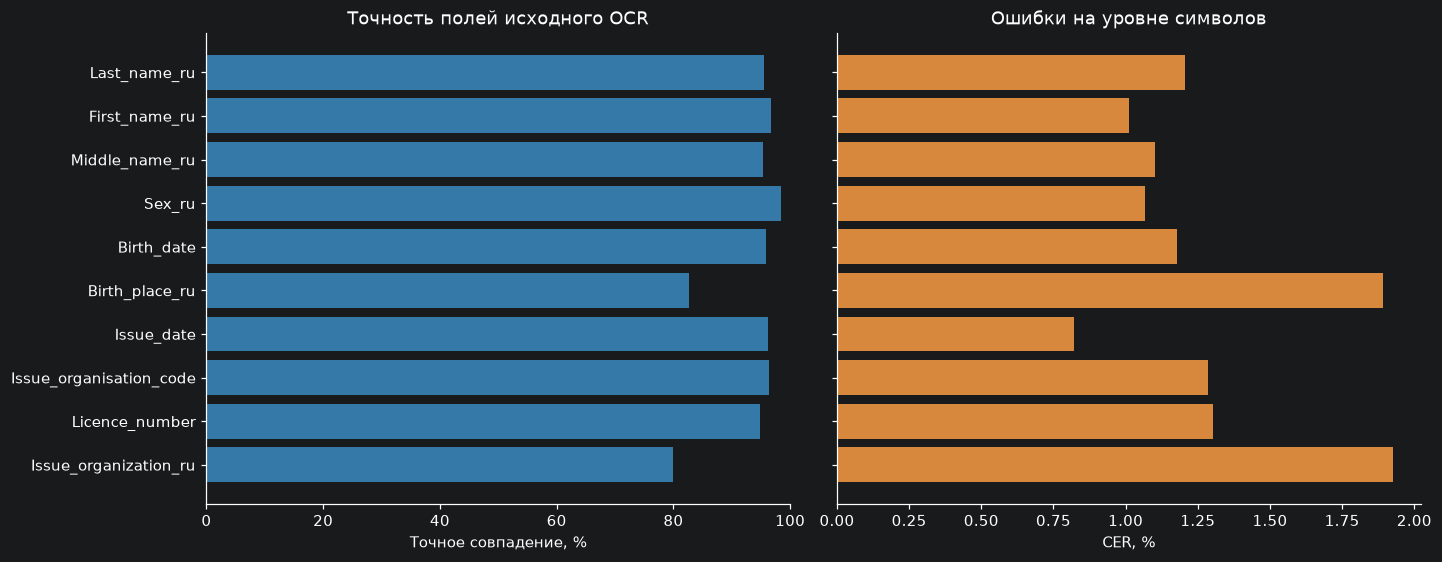

In [80]:
# Вычисляем точность полей и CER из исходных записей.
field_rows = []
field_stats = {}
for field in FIELDS:
    exact = missing = high_confidence_wrong = edit_count = target_characters = 0
    for doc in train_documents:
        value = doc["viz"].get(field)
        text = canonical(field_text(value))
        gold = labels[doc["doc_id"]][field]
        correct = text == canonical(gold)
        exact += correct
        missing += not value
        high_confidence_wrong += bool(value and value.get("conf", 0) >= 0.99 and not correct)
        edit_count += edit_distance(text, gold)
        target_characters += len(gold)
    result = {
        "missing": missing,
        "exact_rate": exact / len(train_documents),
        "cer": edit_count / target_characters if target_characters else 0,
        "wrong_with_field_conf_ge_099": high_confidence_wrong,
    }
    field_stats[field] = result
    field_rows.append(
        {
            "Поле": field,
            "Тип метки": "str",
            "Пропусков VIZ": missing,
            "Exact match": f"{result['exact_rate']:.2%}",
            "CER": f"{result['cer']:.2%}",
            "Ошибок при field conf ≥ .99": high_confidence_wrong,
        }
    )
table(field_rows)
print(
    "Документов с полным исходным совпадением:",
    eda["raw_all_fields_exact"],
    "/",
    len(train_documents),
)
print(
    "Дубликатов полных меток:",
    eda["label_duplicate_documents"],
    "| Пустые эталонные поля:",
    eda["label_empty"],
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
y = np.arange(len(FIELDS))
axes[0].barh(y, [100 * field_stats[f]["exact_rate"] for f in FIELDS], color="#3579a8")
axes[0].set(
    yticks=y,
    yticklabels=FIELDS,
    xlabel="Точное совпадение, %",
    xlim=(0, 100),
    title="Точность полей исходного OCR",
)
axes[1].barh(y, [100 * field_stats[f]["cer"] for f in FIELDS], color="#d8883c")
axes[1].set(yticks=y, yticklabels=[], xlabel="CER, %", title="Ошибки на уровне символов")
for ax in axes:
    ax.invert_yaxis()
plt.show()
eda["fields"] = field_stats

Источник,Train,Доля train,Test,Доля test,Исходный full exact
web,1639,54.63%,890,44.50%,54.73%
mobile,1069,35.63%,679,33.95%,58.00%
mobile_v2,292,9.73%,431,21.55%,55.82%


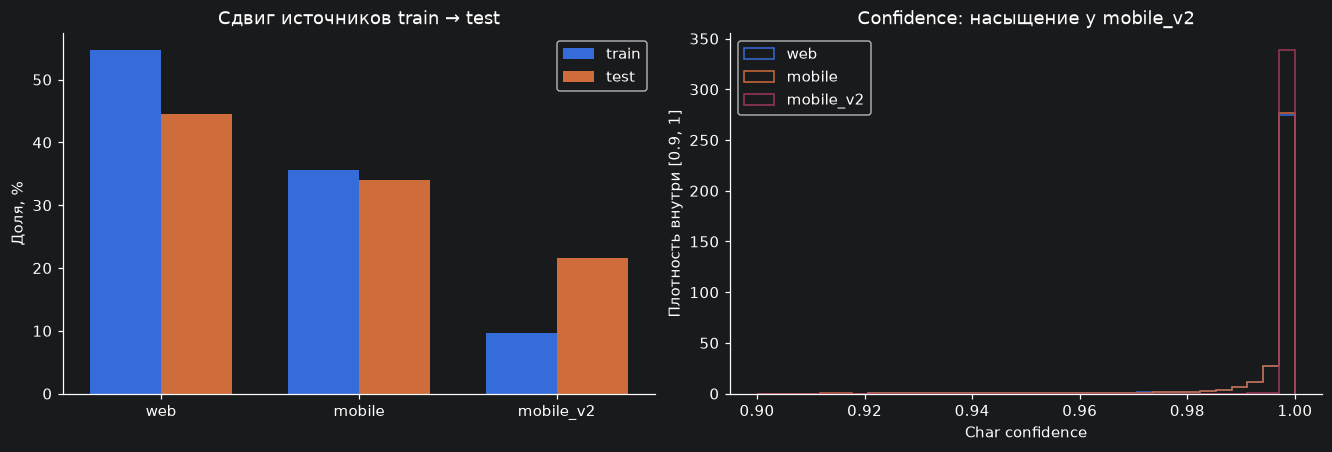

In [81]:
sources = ["web", "mobile", "mobile_v2"]
train_source = Counter(doc["source"] for doc in train_documents)
test_source = Counter(doc["source"] for doc in test_documents)
table(
    [
        {
            "Источник": s,
            "Train": train_source[s],
            "Доля train": f"{train_source[s] / len(train_documents):.2%}",
            "Test": test_source[s],
            "Доля test": f"{test_source[s] / len(test_documents):.2%}",
            "Исходный full exact": f"{np.mean([ok for doc, ok in zip(train_documents, raw_exact) if doc['source'] == s]):.2%}",
        }
        for s in sources
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
x = np.arange(len(sources))
axes[0].bar(
    x - 0.18, [100 * train_source[s] / len(train_documents) for s in sources], 0.36, label="train"
)
axes[0].bar(
    x + 0.18, [100 * test_source[s] / len(test_documents) for s in sources], 0.36, label="test"
)
axes[0].set(xticks=x, xticklabels=sources, ylabel="Доля, %", title="Сдвиг источников train → test")
axes[0].legend()
for source in sources:
    values = [
        c
        for doc in train_documents
        if doc["source"] == source
        for value in doc["viz"].values()
        for c in confidence_values(value)
    ]
    axes[1].hist(values, bins=np.linspace(0.9, 1, 35), histtype="step", density=True, label=source)
axes[1].set(
    xlabel="Char confidence",
    ylabel="Плотность внутри [0.9, 1]",
    title="Confidence: насыщение у mobile_v2",
)
axes[1].legend()
plt.show()

Высокая уверенность OCR не гарантирует правильность: существуют неверные поля с confidence ≥0.99, а у mobile_v2 встречается полное насыщение значениями 1.0. Нельзя перенести наблюдаемую частоту ошибок в train на test без учёта изменившихся долей источников.

Справочник тоже не является эталоном печатной формулировки: одному коду соответствуют несколько названий, а падежи, сокращения и пунктуация отличаются. Поэтому ближайшее название не подставляется автоматически.


In [82]:
eda["reference"] = {
    "codes": len(reference.by_code),
    "ambiguous_codes": sum(len(names) > 1 for names in reference.by_code.values()),
    "label_name_absent_for_code": sum(
        canonical(row["Issue_organization_ru"])
        not in reference.by_code.get(row["Issue_organisation_code"], set())
        for row in labels.values()
    ),
}
table(
    [{"Показатель справочника": key, "Значение": value} for key, value in eda["reference"].items()]
)
# Эксперимент пересчитывается на development-части.
development_ids = set(splits["train"])
ref_experiment = Counter()
for doc in train_documents:
    if doc["doc_id"] not in development_ids:
        continue
    field = "Issue_organization_ru"
    raw = normalize(field, field_text(doc["viz"].get(field)))
    code = normalize(
        "Issue_organisation_code", field_text(doc["viz"].get("Issue_organisation_code"))
    )
    replacement, status, _ = reference.match(code, raw)
    if status != "unique_near":
        continue
    gold = canonical(labels[doc["doc_id"]][field])
    if replacement == gold and raw != gold:
        ref_experiment["fixed"] += 1
    elif raw == gold and replacement != gold:
        ref_experiment["damaged"] += 1
    else:
        ref_experiment["still_wrong"] += 1

table(
    [
        {
            "Эксперимент на development": "Ближайшее название, distance ≤ 2, отрыв ≥ 2",
            "Исправлено": ref_experiment.get("fixed", 0),
            "Испорчено правильных": ref_experiment.get("damaged", 0),
            "Осталось неверным": ref_experiment.get("still_wrong", 0),
        }
    ]
)
report["reference_hypothesis"] = dict(ref_experiment)

Показатель справочника,Значение
codes,7508
ambiguous_codes,5596
label_name_absent_for_code,2823


Эксперимент на development,Исправлено,Испорчено правильных,Осталось неверным
"Ближайшее название, distance ≤ 2, отрыв ≥ 2",10,259,20


## 5. Состав MRZ и контрольные проверки

Нижняя строка внутреннего паспорта содержит номер, короткую дату рождения, пол, дополнительную цифру серии, дату выдачи и код подразделения. Проверяются контрольные цифры номера, даты рождения, дополнительных данных и составная контрольная цифра.

**Контрольные цифры не являются криптографической гарантией.** Ошибка может сохранить checksum; ошибки VIZ и MRZ могут быть зависимыми. Пол находится в позиции, которая не входит в используемые числовые контрольные суммы. ФИО в верхней строке также ими не защищены. Место рождения и название органа выдачи в MRZ вообще отсутствуют.

`trusted_numeric` в коде означает «структура распознана и четыре проверки пройдены», а не «достоверность всех полей доказана».


In [83]:
# Проверки MRZ тоже пересчитываются по фактическим строкам всех train-документов.
mrz_counts = Counter()
mrz_errors = Counter()
for doc in train_documents:
    parsed = parse_mrz(doc.get("mrz"))
    gold = labels[doc["doc_id"]]
    visual_names = {
        field: normalize(field, field_text(doc["viz"].get(field))) for field in FIELDS[:3]
    }
    visual_agreement = names_agree(visual_names, parsed)
    mrz_counts["present"] += parsed.present
    mrz_counts["structure_lower"] += parsed.structure
    mrz_counts["all_checks_pass"] += parsed.trusted_numeric
    mrz_counts["names_agree_gold"] += names_agree(gold, parsed)
    mrz_counts["names_agree_viz"] += visual_agreement
    mrz_counts["names_agree_viz_but_wrong"] += visual_agreement and any(
        visual_names[f] != canonical(gold[f]) for f in FIELDS[:3]
    )
    for check, passed in parsed.checks.items():
        mrz_counts["check_pass:" + check] += passed
    if parsed.trusted_numeric:
        for field in ("Licence_number", "Issue_organisation_code", "Sex_ru"):
            mrz_errors[field] += parsed.values[field] != gold[field]
        for field, key in (("Birth_date", "Birth_date_short"), ("Issue_date", "Issue_date_short")):
            mrz_errors[field] += parse_date(gold[field]).strftime("%y%m%d") != parsed.values[key]
table([{"Наблюдение по MRZ": key, "Документов": value} for key, value in mrz_counts.items()])
table(
    [
        {"Поле": field, "Несовпадений с меткой среди прошедших все checksum": value}
        for field, value in mrz_errors.items()
    ]
)
display(
    Markdown(
        "**Вывод:** числовые проверки полезны на этих данных, но совпадение ФИО VIZ/MRZ наблюдалось и у ошибочных документов. Использовать две зоны как независимые свидетельства с перемножением вероятностей нельзя."
    )
)
eda["mrz"] = {"counts": dict(mrz_counts), "errors_despite_all_checks": dict(mrz_errors)}
report["eda"] = eda

Наблюдение по MRZ,Документов
present,2817
structure_lower,2543
all_checks_pass,2519
names_agree_gold,2454
names_agree_viz,2236
names_agree_viz_but_wrong,11
check_pass:number,2533
check_pass:birth,2535
check_pass:optional,2537
check_pass:composite,2519


Поле,Несовпадений с меткой среди прошедших все checksum
Licence_number,0
Issue_organisation_code,0
Sex_ru,0
Birth_date,0
Issue_date,0


**Вывод:** числовые проверки полезны на этих данных, но совпадение ФИО VIZ/MRZ наблюдалось и у ошибочных документов. Использовать две зоны как независимые свидетельства с перемножением вероятностей нельзя.

## 6. Модель совместной правильности полей

Целевая метка $y=1$: реконструированные десять полей одновременно совпали с разметкой, и эталон прошёл календарные и возрастные проверки. Иначе $y=0$. Разметка используется для построения целевой метки; вход модели состоит из признаков качества OCR.

Признаки: confidence полей и символов, минимумы/средние/квантили, низкоуверенные символы, геометрические зазоры и число строк, source, sharpness/doc_px/glare, согласованность MRZ, результаты checksum, наличие исправлений и признаки справочника.

Для обучения каждый признак стандартизируется **только по обучающей части**. Модель:

$$s(x)=\sigma(b+w^Tz),\qquad z_j=(x_j-\mu_j)/\sigma_j.$$

Минимизируется log loss с L2-штрафом на веса. Обучение выполняется на CPU. Соответствие score наблюдаемой правильности оценивается на отложенных данных.


In [84]:
train_candidates, feature_dicts = prepare_documents(train_documents, reference)
feature_names = list(feature_dicts[0])
X = np.array([[row[name] for name in feature_names] for row in feature_dicts])
y = np.array(
    [
        is_correct(candidate.fields, labels[doc["doc_id"]])
        for doc, candidate in zip(train_documents, train_candidates)
    ]
)
eligible = np.array([candidate.eligible for candidate in train_candidates])
strict_gate = np.array(
    [
        rule_score(doc, candidate, True) >= 0 and evidence_gate(doc, candidate)
        for doc, candidate in zip(train_documents, train_candidates)
    ]
)
print("Матрица признаков:", X.shape, "| Признаков:", len(feature_names))
print(
    "После формально-логических проверок:",
    int(eligible.sum()),
    "| После обязательных подтверждающих проверок:",
    int(strict_gate.sum()),
)
table(
    [
        {"Группа признаков": group, "Число": sum(name.startswith(prefix) for name in feature_names)}
        for group, prefix in [
            ("Поле Birth_place_ru", "Birth_place_ru:"),
            ("Качество изображения", "quality:"),
            ("MRZ", "mrz:"),
            ("Источник", "source:"),
            ("Справочник", "reference:"),
        ]
    ]
)

Матрица признаков: (3000, 138) | Признаков: 138
После формально-логических проверок: 2442 | После обязательных подтверждающих проверок: 1651


Группа признаков,Число
Поле Birth_place_ru,12
Качество изображения,3
MRZ,7
Источник,3
Справочник,3


## 7. Начальный эксперимент: обучение и holdout

Групповое разделение содержит 1798 документов для обучения, 600 для выбора порога и 602 для holdout. Совпадающие номера паспортов или ФИО с датой рождения объединяются в группы до разделения. Seed фиксирован.

Модели с L2-регуляризацией обучаются на train. Для основного режима L2=10 порог выбирается по train и calibration, затем рассчитываются результаты на holdout.

Результаты этого эксперимента использованы при формировании последующей процедуры проверки. Поэтому holdout относится к этапу разработки; независимая оценка окончательной процедуры требует отдельной выборки.


In [85]:
index_by_id = {doc["doc_id"]: i for i, doc in enumerate(train_documents)}
initial_indexes = {name: [index_by_id[doc_id] for doc_id in ids] for name, ids in splits.items()}
table(
    [
        {
            "Часть": name,
            "Документов": len(indexes),
            **dict(Counter(train_documents[i]["source"] for i in indexes)),
        }
        for name, indexes in initial_indexes.items()
    ]
)
fit_indexes = [i for i in initial_indexes["train"] if eligible[i]]
initial_models = {
    f"logistic_l2_{strength:g}": fit_logistic(
        X[fit_indexes], y[fit_indexes].astype(float), strength, feature_names
    )
    for strength in (1.0, 10.0, 100.0)
}
initial_model = initial_models["logistic_l2_10"]
initial_scores = predict(initial_model, X)
development = {name: initial_indexes[name] for name in ["train", "calibration"]}
threshold_rows = evaluate_thresholds(initial_scores, y, development, MODEL_THRESHOLDS, eligible)
initial_choice = max(
    filter(zero_error_trial, threshold_rows), key=lambda row: row["calibration"]["N_accepted"]
)
table(
    [
        {
            "threshold": row["threshold"],
            **{
                f"{name}_{metric}": row[name][key]
                for name in development
                for metric, key in [("accepted", "N_accepted"), ("wrong", "N_wrong_accepted")]
            },
        }
        for row in threshold_rows
    ]
)
print("Выбранный до holdout порог:", initial_choice["threshold"])
initial_policy = {
    "schema_version": 1,
    "as_of": AS_OF.isoformat(),
    "strategy": "risk_model",
    "threshold": initial_choice["threshold"],
    "model": initial_model,
    "selected_without_validation": True,
}
initial_calibration = {"trials": threshold_rows, "selected": initial_choice}

report["initial"]["models"] = initial_models
report["initial"]["policy"] = initial_policy
report["initial"]["calibration"] = initial_calibration

Часть,Документов,web,mobile,mobile_v2
train,1798,983,640,175
calibration,600,328,214,58
validation,602,328,215,59


threshold,train_accepted,train_wrong,calibration_accepted,calibration_wrong
0.9,822,9,265,2
0.95,513,3,162,0
0.975,130,1,40,0
0.98,69,0,28,0
0.985,29,0,12,0
0.99,10,0,6,0
0.995,0,0,2,0
0.9975,0,0,0,0
0.999,0,0,0,0
0.9995,0,0,0,0


Выбранный до holdout порог: 0.98


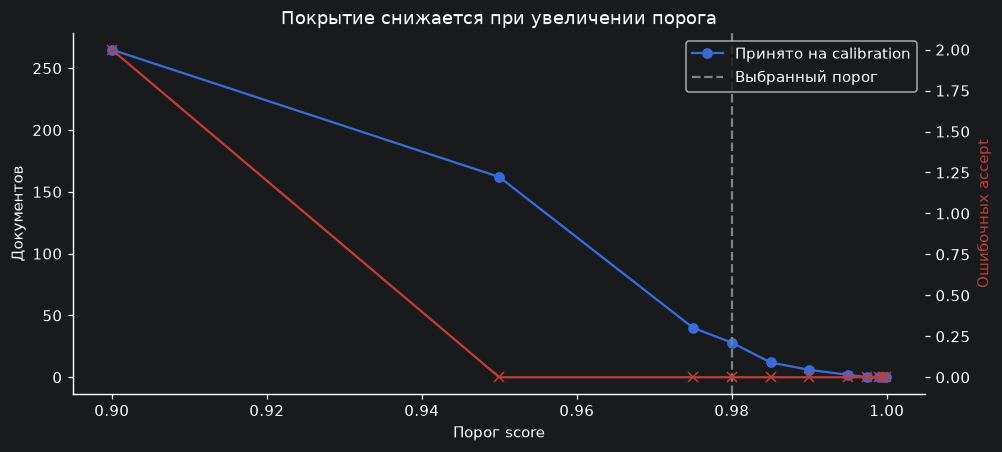

Метод,Модель,Порог,Accepted,Wrong
baseline,None,1.0,24,1
rules,None,1.0,24,1
joint_rules,None,0.999,24,0
risk_model,logistic_l2_10,0.98,29,2
hybrid,logistic_l2_1,0.9975,11,0


**Первый режим на holdout: 2 ошибок среди 29 принятых.**

In [86]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(
    [r["threshold"] for r in threshold_rows],
    [r["calibration"]["N_accepted"] for r in threshold_rows],
    marker="o",
    label="Принято на calibration",
)
ax.set(xlabel="Порог score", ylabel="Документов", title="Покрытие снижается при увеличении порога")
right = ax.twinx()
right.plot(
    [r["threshold"] for r in threshold_rows],
    [r["calibration"]["N_wrong_accepted"] for r in threshold_rows],
    marker="x",
    color="#bd3d38",
    label="Ошибочных accept",
)
right.set_ylabel("Ошибочных accept", color="#bd3d38")
ax.axvline(initial_choice["threshold"], color="gray", linestyle="--", label="Выбранный порог")
ax.legend(loc="upper right")
plt.show()

holdout_indexes = initial_indexes["validation"]
repeated_holdout = metrics(
    y[holdout_indexes].tolist(),
    (
        eligible[holdout_indexes] & (initial_scores[holdout_indexes] >= initial_choice["threshold"])
    ).tolist(),
)
# Для базовых правил сохраняем фиксированные режимы исходного эксперимента.
# Пороги модельных подходов выбираем по train/calibration до оценки holdout.
baseline_thresholds = {"baseline": 1.0, "rules": 1.0, "joint_rules": 0.999}
raw_candidates = [reconstruct(doc, reference, corrected=False) for doc in train_documents]
comparisons = []
live_comparisons = []
for strategy, model_name in [
    ("baseline", None),
    ("rules", None),
    ("joint_rules", None),
    ("risk_model", "logistic_l2_10"),
    ("hybrid", "logistic_l2_1"),
]:
    candidates = raw_candidates if strategy == "baseline" else train_candidates
    strict = strategy in {"joint_rules", "hybrid"}
    gate_scores = np.array(
        [rule_score(doc, candidate, strict) for doc, candidate in zip(train_documents, candidates)]
    )
    scores = (
        np.where(gate_scores >= 0, predict(initial_models[model_name], X), -1)
        if model_name
        else gate_scores
    )
    targets = np.array(
        [
            is_correct(candidate.fields, labels[doc["doc_id"]])
            for doc, candidate in zip(train_documents, candidates)
        ]
    )
    trials = evaluate_thresholds(scores, targets, development, MODEL_THRESHOLDS + [1.0, 1.000001])
    if model_name is None:
        selected = next(row for row in trials if row["threshold"] == baseline_thresholds[strategy])
    else:
        selected = max(
            filter(zero_error_trial, trials),
            key=lambda row: (row["calibration"]["N_accepted"], row["train"]["N_accepted"]),
        )
    accepted = scores[holdout_indexes] >= selected["threshold"]
    measured = metrics(targets[holdout_indexes].tolist(), accepted.tolist())
    comparisons.append(
        {
            "strategy": strategy,
            "model": model_name,
            "threshold": selected["threshold"],
            "validation": measured,
            "calibration_trials": trials,
        }
    )
    live_comparisons.append(
        {
            "Метод": strategy,
            "Модель": model_name,
            "Порог": selected["threshold"],
            "Accepted": measured["N_accepted"],
            "Wrong": measured["N_wrong_accepted"],
        }
    )
table(live_comparisons)
initial_accept = eligible & (initial_scores >= initial_choice["threshold"])
holdout_errors = audit_errors(
    [train_documents[i] for i in holdout_indexes],
    [train_candidates[i] for i in holdout_indexes],
    y[holdout_indexes],
    initial_accept[holdout_indexes],
    labels,
    initial_scores[holdout_indexes],
    "initial_holdout",
)
initial_validation = {"final": repeated_holdout, "comparisons": comparisons}
report["initial"]["validation"] = initial_validation
report["initial"]["errors"] = holdout_errors
development_indexes = initial_indexes["train"] + initial_indexes["calibration"]
report["initial"]["development_errors"] = audit_errors(
    [train_documents[i] for i in development_indexes],
    [train_candidates[i] for i in development_indexes],
    y[development_indexes],
    (eligible & (initial_scores >= 0.9))[development_indexes],
    labels,
    initial_scores[development_indexes],
    "initial_logistic_threshold_0.9",
)
display(
    Markdown(
        f"**Первый режим на holdout: {repeated_holdout['N_wrong_accepted']} ошибок среди {repeated_holdout['N_accepted']} принятых.**"
    )
)

## 8. Вложенная кросс-валидация

Процедура включает проверки MRZ, согласованности ФИО, полноты строк, confidence и поддерживаемого века рождения. Используются пять внешних групповых фолдов. Внутри каждой обучающей части выделяется отдельная calibration-часть.

Для каждого внешнего фолда обучаются три модели с разной L2-регуляризацией. Стандартизация, веса, L2 и порог рассчитываются без использования соответствующего внешнего фолда.

Архитектура процедуры сформирована с учётом начального holdout. Кросс-валидация оценивает эту процедуру внутри имеющегося датасета; адаптация архитектуры к данным учитывается как ограничение оценки.


In [87]:
folds = grouped_folds(train_documents, labels)
oof_accept = np.zeros(len(train_documents), dtype=bool)
oof_scores = np.full(len(train_documents), -1.0)
fold_rows = []
oof_errors = []
for fold_number, outer_indexes in enumerate(folds):
    outer_set = set(outer_indexes)
    inner_documents = [doc for i, doc in enumerate(train_documents) if i not in outer_set]
    inner_split = make_split(inner_documents, labels)
    fit_ids = set(inner_split["train"] + inner_split["validation"])
    cal_ids = set(inner_split["calibration"])
    fit = [i for i, doc in enumerate(train_documents) if doc["doc_id"] in fit_ids]
    cal = [i for i, doc in enumerate(train_documents) if doc["doc_id"] in cal_ids]
    winner, model, _ = select_policy(fit, cal, X, y, strict_gate, feature_names)
    fold_scores = predict(model, X[outer_indexes])
    accepted = strict_gate[outer_indexes] & (fold_scores >= winner["threshold"])
    oof_accept[outer_indexes] = accepted
    oof_scores[outer_indexes] = fold_scores
    m = metrics(y[outer_indexes].tolist(), accepted.tolist())
    oof_errors.extend(
        audit_errors(
            [train_documents[i] for i in outer_indexes],
            [train_candidates[i] for i in outer_indexes],
            y[outer_indexes],
            accepted,
            labels,
            fold_scores,
            f"nested_outer_{fold_number}",
        )
    )
    fold_rows.append(
        {
            "Фолд": fold_number,
            "Всего": len(outer_indexes),
            "Модель": winner["model"],
            "Порог": winner["threshold"],
            "Accepted": m["N_accepted"],
            "Wrong": m["N_wrong_accepted"],
        }
    )
    print(
        "Фолд",
        fold_number,
        "завершён:",
        m["N_accepted"],
        "accept /",
        m["N_wrong_accepted"],
        "ошибок",
        flush=True,
    )
table(fold_rows)
cv_metrics = metrics(y.tolist(), oof_accept.tolist())
print("Результат вложенной CV:", cv_metrics)
report["outer_folds"] = [[train_documents[i]["doc_id"] for i in fold] for fold in folds]
fold_by_index = {index: number for number, fold in enumerate(folds) for index in fold}
report["cross_validation"]["oof"] = [
    {
        "doc_id": doc["doc_id"],
        "outer_fold": fold_by_index[i],
        "source": doc["source"],
        "score": float(oof_scores[i]),
        "accepted": bool(oof_accept[i]),
        "correct": bool(y[i]),
        "gate": bool(strict_gate[i]),
    }
    for i, doc in enumerate(train_documents)
]
report["cross_validation"]["errors"] = oof_errors

Фолд 0 завершён: 74 accept / 1 ошибок
Фолд 1 завершён: 3 accept / 0 ошибок
Фолд 2 завершён: 31 accept / 1 ошибок
Фолд 3 завершён: 57 accept / 1 ошибок
Фолд 4 завершён: 81 accept / 0 ошибок


Фолд,Всего,Модель,Порог,Accepted,Wrong
0,601,logistic_l2_1,0.9975,74,1
1,600,logistic_l2_10,0.995,3,0
2,600,logistic_l2_1,0.999,31,1
3,598,logistic_l2_1,0.9975,57,1
4,601,logistic_l2_1,0.9975,81,0


Результат вложенной CV: {'N_total': 3000, 'N_accepted': 246, 'N_rejected': 2754, 'N_correct_accepted': 243, 'N_wrong_accepted': 3, 'acceptance_rate': 0.082, 'false_acceptance_rate': 0.012195121951219513, 'precision_among_accepted': 0.9878048780487805, 'error_upper_95_one_sided': 0.031215554563757332, 'rule_of_three': None}


source,Всего,Accepted,Wrong,Покрытие,Риск среди принятых
web,1639,144,3,8.79%,2.08%
mobile,1069,102,0,9.54%,0.00%
mobile_v2,292,0,0,0.00%,не определён


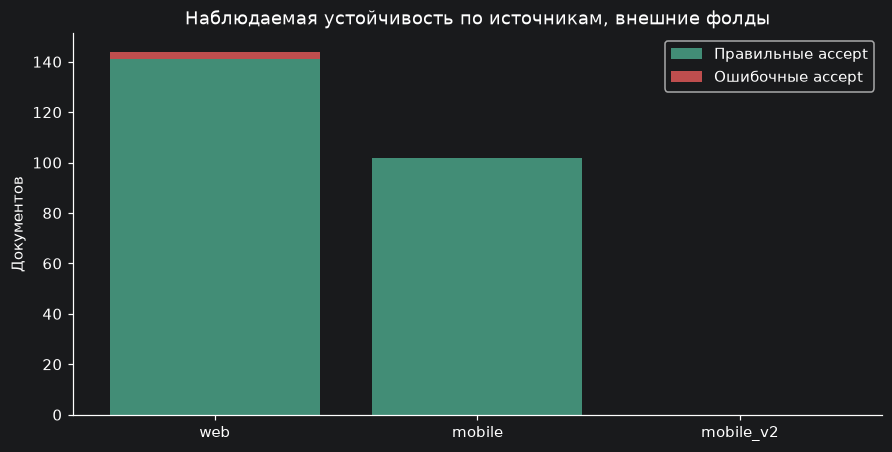

doc_id,source,Ошибочные поля,Score,Причины
tr_00125,web,Birth_place_ru,0.99998741,ocr_substitution
tr_02429,web,"Birth_place_ru, Issue_organization_ru",0.99999908,ocr_substitution
tr_00747,web,Last_name_ru,0.99803683,high_confidence_ocr_error


In [88]:
source_cv = []
cv_by_source = {}
for source in sources:
    indexes = [i for i, doc in enumerate(train_documents) if doc["source"] == source]
    m = metrics(y[indexes].tolist(), oof_accept[indexes].tolist())
    cv_by_source[source] = m
    source_cv.append(
        {
            "source": source,
            "Всего": m["N_total"],
            "Accepted": m["N_accepted"],
            "Wrong": m["N_wrong_accepted"],
            "Покрытие": f"{m['acceptance_rate']:.2%}",
            "Риск среди принятых": f"{m['false_acceptance_rate']:.2%}"
            if m["false_acceptance_rate"] is not None
            else "не определён",
        }
    )
table(source_cv)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(
    sources,
    [r["Accepted"] - r["Wrong"] for r in source_cv],
    label="Правильные accept",
    color="#428d76",
)
ax.bar(
    sources,
    [r["Wrong"] for r in source_cv],
    bottom=[r["Accepted"] - r["Wrong"] for r in source_cv],
    label="Ошибочные accept",
    color="#bf4e4e",
)
ax.set(ylabel="Документов", title="Наблюдаемая устойчивость по источникам, внешние фолды")
ax.legend()
plt.show()
errors = oof_errors
table(
    [
        {
            "doc_id": row["doc_id"],
            "source": row["source"],
            "Ошибочные поля": ", ".join(row["wrong_fields"]),
            "Score": f"{row['score']:.8f}",
            "Причины": ", ".join(row["causes"]),
        }
        for row in errors
    ]
)

### Ограничение источника: mobile

Во внешних фолдах ошибки обнаружены у web. Для mobile получено 102 принятых документа без наблюдаемых ошибок; у mobile_v2 принятых документов нет. Финальная политика разрешает источник mobile.

Ограничение выбрано по результатам CV, поэтому 102/0 является диагностикой выбранного источника. Для статистической границы применяется поправка на три исследованных источника. Зависимость cross-fit результатов и адаптация архитектуры ограничивают интерпретацию этой границы. Подтверждение окончательной политики требует отдельного внешнего holdout.


## 9. Калибровка score модели

Калибровка оценивается сравнением среднего score с фактической долей правильных документов во внешних фолдах. Для редких ошибок особенно важен верхний хвост score: модель может быть уверенной именно там, где данных для оценки риска мало.

Brier score — среднее $(s-y)^2$; меньше лучше. Он диагностирует вероятностные прогнозы, но сам по себе не ограничивает долю ошибочных accept в выбранном хвосте.


Диапазон,N,Средний score,Доля правильных
"[0,0.9]",416,0.16161590234404083,0.16346153846153846
"[0.9,0.99]",574,0.9708018334384754,0.9738675958188153
"[0.99,0.995]",206,0.9927511088637669,0.9854368932038835
"[0.995,0.999]",317,0.9971864341171127,0.9873817034700315
"[0.999,1]",138,0.9995508138800937,0.9855072463768116


Brier на прошедших обязательные проверки: 0.030734910932703495


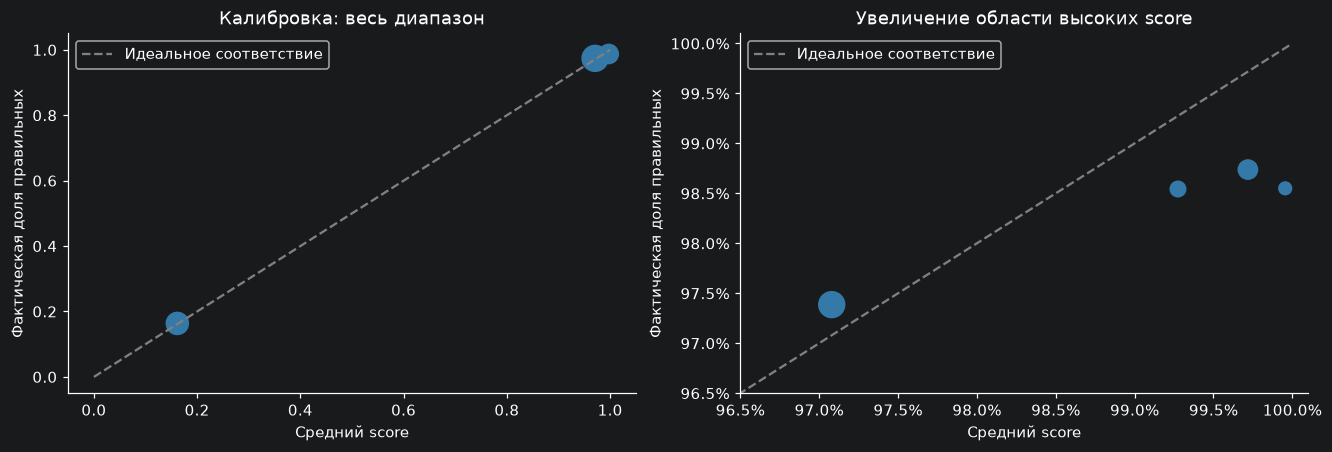

В верхнем диапазоне наблюдаемая правильность ниже среднего score. Поэтому сумму `1 - score` **не используем как достоверный прогноз числа ошибок test**.

In [89]:
reliability = []
for low, high in [(0, 0.9), (0.9, 0.99), (0.99, 0.995), (0.995, 0.999), (0.999, 1.000001)]:
    idx = np.flatnonzero(strict_gate & (oof_scores >= low) & (oof_scores < high))
    if len(idx):
        reliability.append(
            {
                "Диапазон": f"[{low},{min(high, 1)}]",
                "N": len(idx),
                "Средний score": float(oof_scores[idx].mean()),
                "Доля правильных": float(y[idx].mean()),
            }
        )
table(reliability)
print(
    "Brier на прошедших обязательные проверки:",
    float(np.mean((oof_scores[strict_gate] - y[strict_gate]) ** 2)),
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Идеальное соответствие")
    ax.scatter(
        [r["Средний score"] for r in reliability],
        [r["Доля правильных"] for r in reliability],
        s=[r["N"] / 2 for r in reliability],
        color="#3579a8",
    )
    ax.set(xlabel="Средний score", ylabel="Фактическая доля правильных")
    ax.legend()
axes[0].set_title("Калибровка: весь диапазон")
axes[1].set(xlim=(0.965, 1.001), ylim=(0.965, 1.001), title="Увеличение области высоких score")
axes[1].xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=1))
axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=1))
plt.show()
display(
    Markdown(
        "В верхнем диапазоне наблюдаемая правильность ниже среднего score. Поэтому сумму `1 - score` **не используем как достоверный прогноз числа ошибок test**."
    )
)

## 10. Финальное обучение, сохранение модели и обработка test

Модель обучается на train-документах вне calibration; calibration используется для выбора L2 и порога. Прежний holdout уже относится к development, поэтому оценка на всех train не является независимой.

Полученные веса и параметры сохраняются в `artifacts/policy.json`. Эта же новая модель используется для записи `answers.jsonl`. Существующий файл модели не читается.


### Функции применения обученной модели

Эти определения вызываются после обучения. CLI использует те же ячейки с тегом `passport-inference`, чтобы обрабатывать новые документы без Jupyter и исследовательских библиотек.


In [90]:
import argparse
import logging
import os
import tempfile

In [91]:
def logistic_probability(model, values):
    score = model["intercept"] + sum(
        weight * ((values[name] - center) / scale)
        for name, weight, center, scale in zip(
            model["features"], model["weights"], model["center"], model["scale"]
        )
    )
    return 1 / (1 + math.exp(-max(-700, min(700, score))))


class Processor:
    def __init__(self, root, config=None):
        self.reference = Subdivisions(root / "reference" / "subdivisions.csv")
        self.config = (
            config
            if config is not None
            else json.loads((root / "artifacts" / "policy.json").read_text(encoding="utf-8"))
        )

    def inspect(self, document):
        candidate = reconstruct(document, self.reference)
        mode = self.config["strategy"]
        strict = mode in {"joint_rules", "hybrid", "evidence_rules", "evidence_hybrid"}
        score = rule_score(document, candidate, strict)
        if mode.startswith("evidence_") and not evidence_gate(document, candidate):
            score = -1
        if mode in {"risk_model", "hybrid", "evidence_hybrid"} and score >= 0:
            score = logistic_probability(self.config["model"], features(document, candidate))
        allowed_sources = self.config.get("allowed_sources", ["web", "mobile", "mobile_v2"])
        accept = score >= self.config["threshold"] and document.get("source") in allowed_sources
        return candidate, score, accept

    def process(self, document):
        candidate, _, accept = self.inspect(document)
        output = {
            "doc_id": document["doc_id"],
            "decision": "accept" if accept else "reject",
        }
        if accept:
            output["fields"] = candidate.fields
        return output

In [92]:
LOGGER = logging.getLogger(__name__)


def run(input_path, output_path, processor):
    if input_path.resolve() == output_path.resolve():
        raise ValueError("Input and output paths must differ")
    total = accepted = 0
    # Atomic replacement prevents a failed batch from leaving a partial submission.
    descriptor, temporary = tempfile.mkstemp(
        prefix=".passport-", suffix=".jsonl", dir=output_path.parent
    )
    try:
        with (
            os.fdopen(descriptor, "w", encoding="utf-8") as target,
            input_path.open(encoding="utf-8") as source,
        ):
            for line_number, line in enumerate(source, 1):
                try:
                    document = json.loads(line)
                except json.JSONDecodeError as exc:
                    # A broken JSON line has no recoverable, trustworthy doc_id.
                    raise ValueError(
                        f"Invalid JSON at line {line_number}; output not replaced"
                    ) from exc
                if not isinstance(document, dict) or not isinstance(document.get("doc_id"), str):
                    raise ValueError(
                        f"Missing string doc_id at line {line_number}; output not replaced"
                    )
                try:
                    result = processor.process(document)
                except (ValueError, TypeError, KeyError, AttributeError, OverflowError) as exc:
                    LOGGER.warning(
                        "Rejected malformed OCR at line %d (%s)", line_number, type(exc).__name__
                    )
                    result = {"doc_id": document["doc_id"], "decision": "reject"}
                target.write(json.dumps(result, ensure_ascii=False, allow_nan=False) + "\n")
                total += 1
                accepted += result["decision"] == "accept"
        os.replace(temporary, output_path)
    finally:
        Path(temporary).unlink(missing_ok=True)
    return total, accepted


def main(argv=None, root=None):
    parser = argparse.ArgumentParser(description="Offline passport OCR postprocessing")
    parser.add_argument("input", type=Path)
    parser.add_argument("output", type=Path)
    args = parser.parse_args(argv)
    logging.basicConfig(level=logging.WARNING, format="%(levelname)s: %(message)s")
    try:
        total, accepted = run(
            args.input, args.output, Processor(root if root is not None else Path.cwd())
        )
    except (OSError, ValueError) as exc:
        parser.exit(1, f"{exc}\n")
    print(f"documents={total} accepted={accepted} rejected={total - accepted}")

In [93]:
final_cal_ids = set(splits["calibration"])
final_fit = [i for i, doc in enumerate(train_documents) if doc["doc_id"] not in final_cal_ids]
final_cal = [i for i, doc in enumerate(train_documents) if doc["doc_id"] in final_cal_ids]
final_choice, retrained_final, final_trials = select_policy(
    final_fit, final_cal, X, y, strict_gate, feature_names
)
policy = {
    "schema_version": 1,
    "as_of": AS_OF.isoformat(),
    "strategy": "evidence_hybrid",
    "threshold": final_choice["threshold"],
    "model": retrained_final,
    "selection": {
        "model": final_choice["model"],
        "train": final_choice["train"],
        "calibration": final_choice["calibration"],
    },
    "allowed_sources": ["mobile"],
    "source_selection": "posthoc_after_nested_cv",
}
save_json("artifacts/policy.json", policy)
processor = Processor(PROJECT_ROOT, config=policy)
table(
    [
        {
            "Обучение": len(final_fit),
            "Calibration": len(final_cal),
            "Модель": final_choice["model"],
            "Порог": final_choice["threshold"],
            "Разрешённый source": ", ".join(policy["allowed_sources"]),
        }
    ]
)
table(
    [
        {
            "Модель": row["model"],
            "Порог": row["threshold"],
            "Train accepted": row["train"]["N_accepted"],
            "Train wrong": row["train"]["N_wrong_accepted"],
            "Calibration accepted": row["calibration"]["N_accepted"],
            "Calibration wrong": row["calibration"]["N_wrong_accepted"],
        }
        for row in final_trials
    ]
)
total, accepted = run(
    PROJECT_ROOT / "data/test_predictions.jsonl", PROJECT_ROOT / "answers.jsonl", processor
)
train_total, train_accepted = run(
    PROJECT_ROOT / "data/train_predictions.jsonl",
    RESULTS_DIR / "train_answers.jsonl",
    processor,
)
train_outputs = read_jsonl(RESULTS_DIR / "train_answers.jsonl")
train_final_metrics = metrics(y.tolist(), [row["decision"] == "accept" for row in train_outputs])
report["cross_validation"]["summary"] = {
    "protocol": "five grouped outer folds, inner grouped calibration; scaler, weights, L2 and threshold exclude each outer fold",
    "adaptivity_limitation": "architecture adapted after initial holdout; final source restriction selected posthoc",
    "overall": cv_metrics,
    "by_source": cv_by_source,
    "folds": fold_rows,
    "final_selected": final_choice,
    "final_trials": final_trials,
}
print("Обученная модель сохранена: artifacts/policy.json")
print("Test:", total, "документов;", accepted, "accept;", total - accepted, "reject")

Обучение,Calibration,Модель,Порог,Разрешённый source
2400,600,logistic_l2_1,0.995,mobile


Модель,Порог,Train accepted,Train wrong,Calibration accepted,Calibration wrong
logistic_l2_1,0.995,364,0,88,0
logistic_l2_1,0.9975,205,0,52,0
logistic_l2_1,0.999,76,0,20,0
logistic_l2_1,0.9995,34,0,7,0
logistic_l2_1,0.9999,7,0,1,0
logistic_l2_1,1.000001,0,0,0,0
logistic_l2_10,0.995,14,0,6,0
logistic_l2_10,0.9975,4,0,2,0
logistic_l2_10,0.999,1,0,1,0
logistic_l2_10,0.9995,1,0,1,0


Обученная модель сохранена: artifacts/policy.json
Test: 2000 документов; 105 accept; 1895 reject


### Влияние восстановления на покрытие

Сравниваются два режима: допуск восстановленных реквизитов и дополнительное отклонение всех документов с восстановлением. Веса модели и порог фиксированы; меняется только правило допуска таких документов.


In [94]:
test_candidates = [reconstruct(doc, reference) for doc in test_documents]
train_recovered = [
    [f for f, mode in candidate.changes.items() if mode == "mrz_missing"]
    for candidate in train_candidates
]
test_recovered = [
    [f for f, mode in candidate.changes.items() if mode == "mrz_missing"]
    for candidate in test_candidates
]
test_outputs = read_jsonl(PROJECT_ROOT / "answers.jsonl")
train_accept = np.array([out["decision"] == "accept" for out in train_outputs])
test_accept = np.array([out["decision"] == "accept" for out in test_outputs])
train_has_recovery = np.array(list(map(bool, train_recovered)))
test_has_recovery = np.array(list(map(bool, test_recovered)))
no_recovery_test_accept = test_accept & ~test_has_recovery

table(
    [
        {
            "Проверка текущей фиксированной политики": name,
            "Train (in-sample)": int(train),
            "Test": int(test),
        }
        for name, train, test in [
            ("Принято без запрета восстановления", train_accept.sum(), test_accept.sum()),
            (
                "Дополнительно отклонить все документы с восстановлением",
                (train_accept & ~train_has_recovery).sum(),
                no_recovery_test_accept.sum(),
            ),
            (
                "Accept с восстановленным полем",
                (train_accept & train_has_recovery).sum(),
                (test_accept & test_has_recovery).sum(),
            ),
        ]
    ]
)
example_index = next(
    i for i in range(len(train_documents)) if train_accept[i] and train_recovered[i] == ["Sex_ru"]
)
doc, candidate = train_documents[example_index], train_candidates[example_index]
table(
    [
        {
            "doc_id": doc["doc_id"],
            "Источник": doc["source"],
            "VIZ: Sex_ru": field_text(doc["viz"].get("Sex_ru")) or "поле отсутствует",
            "MRZ → кандидат": candidate.fields["Sex_ru"],
            "Метка train, только для сверки": labels[doc["doc_id"]]["Sex_ru"],
        }
    ]
)
display(
    Markdown(
        "В сравнении фиксированы веса модели и порог; варьируется правило допуска документов с восстановленными полями."
    )
)

Проверка текущей фиксированной политики,Train (in-sample),Test
Принято без запрета восстановления,174,105
Дополнительно отклонить все документы с восстановлением,154,97
Accept с восстановленным полем,20,8


doc_id,Источник,VIZ: Sex_ru,MRZ → кандидат,"Метка train, только для сверки"
tr_00150,mobile,поле отсутствует,ЖЕН.,ЖЕН.


В сравнении фиксированы веса модели и порог; варьируется правило допуска документов с восстановленными полями.

Восстановление участвует в 8 принятых test-документах. Дополнительный запрет уменьшает число accept со 105 до 97 при фиксированных весах и пороге. Это сравнение оценивает изменение покрытия; восстановление пола отдельно учитывается как ветка без защиты символа пола контрольными суммами MRZ.


## 11. Статистическая неопределённость частоты ошибок

Для 0 ошибок среди $n$ независимых принятых документов односторонняя 95% биномиальная верхняя граница равна:

$$p_{upper}=1-0.05^{1/n}.$$

Приближение Rule of Three составляет $3/n$. Обе величины характеризуют верхнюю границу доли ошибок при биномиальном предположении.

Для учёта выбора среди трёх источников применяется поправка Бонферрони: $\alpha=0.05/3$. Пересечение обучающих данных во внешних фолдах и адаптация архитектуры ограничивают точность номинальной гарантии этой оценки.


Оценка неопределённости,Значение
Наблюдаемый риск,0/102 = 0.00% (только наблюдение)
"Односторонняя 95% граница, биномиальное допущение",2.894%
Rule of Three,2.941%
Граница с поправкой на 3 источника,3.935%
Независимых accept без ошибок для границы ≤0.1%,2995


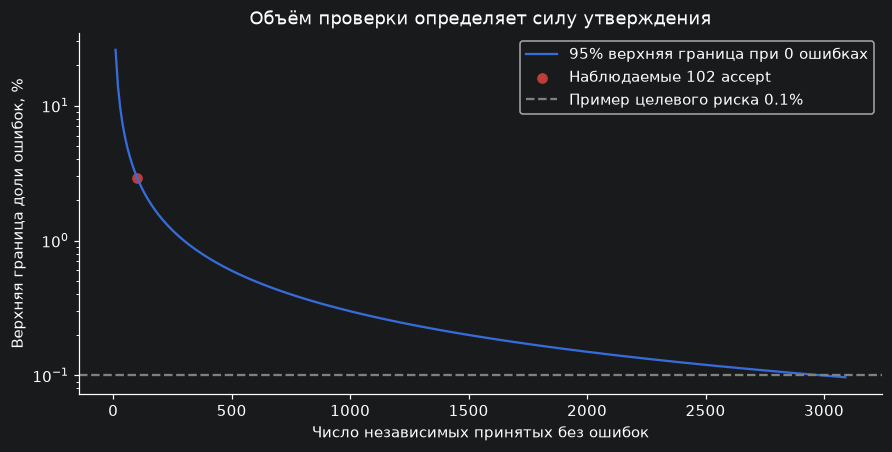

In [95]:
n = next(row["Accepted"] for row in source_cv if row["source"] == "mobile")
mobile_wrong = cv_by_source["mobile"]["N_wrong_accepted"]
plain = binomial_upper(mobile_wrong, n)
adjusted = binomial_upper(mobile_wrong, n, alpha=0.05 / len(sources))
needed = math.ceil(math.log(0.05) / math.log(1 - 0.001))
table(
    [
        {
            "Оценка неопределённости": "Наблюдаемый риск",
            "Значение": f"{mobile_wrong}/{n} = {mobile_wrong / n:.2%} (только наблюдение)",
        },
        {
            "Оценка неопределённости": "Односторонняя 95% граница, биномиальное допущение",
            "Значение": f"{plain:.3%}",
        },
        {"Оценка неопределённости": "Rule of Three", "Значение": f"{3 / n:.3%}"},
        {
            "Оценка неопределённости": "Граница с поправкой на 3 источника",
            "Значение": f"{adjusted:.3%}",
        },
        {
            "Оценка неопределённости": "Независимых accept без ошибок для границы ≤0.1%",
            "Значение": needed,
        },
    ]
)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
counts = np.arange(10, 3100, 10)
ax.plot(counts, 100 * (1 - 0.05 ** (1 / counts)), label="95% верхняя граница при 0 ошибках")
ax.scatter([n], [100 * plain], color="#bd3d38", label=f"Наблюдаемые {n} accept")
ax.axhline(0.1, linestyle="--", color="gray", label="Пример целевого риска 0.1%")
ax.set(
    xlabel="Число независимых принятых без ошибок",
    ylabel="Верхняя граница доли ошибок, %",
    yscale="log",
    title="Объём проверки определяет силу утверждения",
)
ax.legend()
plt.show()

## 12. Прогноз ошибок на test

Для mobile во внешних фолдах наблюдалось 0 ошибок среди 102 принятых документов. При априорном распределении Jeffreys Beta(0.5,0.5) апостериорное распределение риска составляет Beta(0.5,102.5).

Для 105 test-accept условное ожидаемое число ошибок равно:

$$E[W]=105\cdot\frac{0.5}{103}\approx0.51.$$

Центральный 95% апостериорный прогнозный интервал числа ошибок составляет 0–3. Произведение количества accept на верхнюю границу доли ошибок с поправкой на источники равно 4.13 и характеризует верхнюю границу ожидаемого количества ошибок при принятых допущениях.

Расчёт предполагает переносимость риска внутри mobile. При интерпретации учитываются выбор источника по результатам CV, адаптация архитектуры и зависимость cross-fit исходов.


Результат test,Значение
Всего / accept / reject,2000 / 105 / 1895
Покрытие среди всех test,5.25%
Условное ожидаемое число ошибок,0.5097
95% posterior predictive interval,0–3
Ориентир верхней границы ожидаемого числа,4.1313


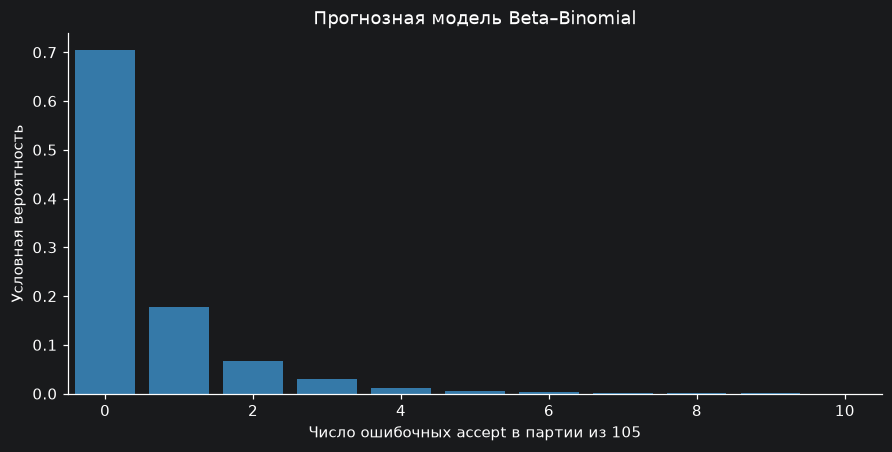

Обучение, CV и применение модели завершены.
Модель, разбиения, ответы и отчёты созданы из исходных данных.


In [96]:
posterior_mean = (mobile_wrong + 0.5) / (n + 1)
expected = accepted * posterior_mean
rng = np.random.default_rng(SEED)
probabilities = rng.beta(mobile_wrong + 0.5, n - mobile_wrong + 0.5, size=100000)
error_draws = rng.binomial(accepted, probabilities)
predictive = np.quantile(error_draws, [0.025, 0.975], method="inverted_cdf").astype(int)
upper_expected = accepted * adjusted
table(
    [
        {
            "Результат test": "Всего / accept / reject",
            "Значение": f"{total} / {accepted} / {total - accepted}",
        },
        {"Результат test": "Покрытие среди всех test", "Значение": f"{accepted / total:.2%}"},
        {"Результат test": "Условное ожидаемое число ошибок", "Значение": f"{expected:.4f}"},
        {
            "Результат test": "95% posterior predictive interval",
            "Значение": f"{predictive[0]}–{predictive[1]}",
        },
        {
            "Результат test": "Ориентир верхней границы ожидаемого числа",
            "Значение": f"{upper_expected:.4f}",
        },
    ]
)
values, frequencies = np.unique(error_draws, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(values, frequencies / len(error_draws), color="#3579a8")
ax.set(
    xlabel=f"Число ошибочных accept в партии из {accepted}",
    ylabel="Условная вероятность",
    xlim=(-0.5, 10.5),
    title="Прогнозная модель Beta–Binomial",
)
plt.show()
print("Обучение, CV и применение модели завершены.")
final_report = {
    "allowed_sources": policy["allowed_sources"],
    "source_selection_is_posthoc": True,
    "restricted_oof_diagnostic": cv_by_source["mobile"],
    "restricted_oof_simultaneous_source_95_error_upper_binomial": adjusted,
    "N_total": total,
    "N_accepted": accepted,
    "N_rejected": total - accepted,
    "acceptance_rate": accepted / total,
    "expected_wrong_accepted_jeffreys": expected,
    "upper_expected_wrong_accepted_simultaneous_95_binomial": upper_expected,
    "posterior_predictive_wrong_95_interval": predictive.tolist(),
    "all_train_in_sample": train_final_metrics,
    "assumptions_and_limits": [
        "risk transfer within mobile",
        "posthoc source selection",
        "architecture adapted to the dataset",
        "dependent cross-fit outcomes",
    ],
}
report["final"] = final_report
print("Модель, разбиения, ответы и отчёты созданы из исходных данных.")

save_json("experiments/results/report.json", report)

## 13. Тесты модели и CLI

6 тестов проверяют применение обученной модели, формат JSONL, обработку ошибок, разбиения и согласованность сохранённых параметров. Вместе с 22 тестами предобработки выполняются 28 тестов.


In [97]:
import shutil
import subprocess
import unittest

# Подключаем только определения тестовых примеров из первого notebook.
for cell_index, definition_cell in enumerate(preprocessing_notebook["cells"]):
    if definition_cell["cell_type"] == "code" and "passport-test-support" in definition_cell.get(
        "metadata", {}
    ).get("tags", []):
        exec(
            compile(
                "".join(definition_cell["source"]), f"preprocessing.ipynb:cell-{cell_index}", "exec"
            ),
            globals(),
        )
fields = globals()["fields"]
mrz_for = globals()["mrz_for"]
document = globals()["document"]

In [98]:
class CLITests(unittest.TestCase):
    def test_deterministic_full_cli_and_malformed_ocr(self):
        with tempfile.TemporaryDirectory() as directory:
            root = Path(directory)
            source = root / "input.jsonl"
            docs = [
                document(),
                {"doc_id": "empty", "source": "web", "viz": None},
                {"doc_id": "broken", "source": "web", "viz": {"Birth_place_ru": {"lines": 7}}},
            ]
            source.write_text("".join(json.dumps(p, ensure_ascii=False) + "\n" for p in docs))
            outputs = []
            for name in ("a", "b"):
                target = root / (name + ".jsonl")
                result = subprocess.run(
                    [
                        sys.executable,
                        "-S",
                        str(PROJECT_ROOT / "postprocess.py"),
                        str(source),
                        str(target),
                    ],
                    cwd=directory,
                    capture_output=True,
                    text=True,
                )
                self.assertEqual(result.returncode, 0, result.stderr)
                rows = [json.loads(line) for line in target.read_text().splitlines()]
                self.assertEqual([x["doc_id"] for x in rows], [p["doc_id"] for p in docs])
                self.assertTrue(all(x["decision"] == "reject" for x in rows[1:]))
                for x in rows:
                    self.assertIn(x["decision"], {"accept", "reject"})
                    self.assertEqual(
                        set(x.get("fields", {})),
                        set(FIELDS) if x["decision"] == "accept" else set(),
                    )
                outputs.append(target.read_bytes())
            self.assertEqual(*outputs)

    def test_invalid_json_is_atomic(self):
        with tempfile.TemporaryDirectory() as directory:
            root = Path(directory)
            source, target = root / "input", root / "output"
            source.write_text('{"doc_id":"a"}\nthis is broken\n')
            target.write_text("previous complete output")
            with self.assertRaises(ValueError):
                run(source, target, Processor(PROJECT_ROOT))
            self.assertEqual(target.read_text(), "previous complete output")

    def test_same_file_prevented_and_unknown_source_rejected(self):
        processor = Processor(PROJECT_ROOT)
        with self.assertRaises(ValueError):
            run(PROJECT_ROOT / "answers.jsonl", PROJECT_ROOT / "answers.jsonl", processor)
        doc = document()
        doc["source"] = "unknown"
        self.assertEqual(processor.process(doc)["decision"], "reject")

    def test_saved_artifact_and_numeric_stability(self):
        processor = Processor(PROJECT_ROOT)
        self.assertEqual(processor.config["as_of"], "2026-10-01")
        for bias in (-10000.0, 10000.0):
            probability = logistic_probability(
                {"intercept": bias, "features": [], "weights": [], "center": [], "scale": []}, {}
            )
            self.assertTrue(0 <= probability <= 1)

In [99]:
class ArtifactTests(unittest.TestCase):
    def test_grouped_split_has_no_shared_passport_or_identity(self):
        labels = {
            row["doc_id"]: row["fields"]
            for row in read_jsonl(PROJECT_ROOT / "data/train_labels.jsonl")
        }
        saved = json.loads((RESULTS_DIR / "report.json").read_text())
        for partition in (list(saved["splits"].values()), saved["outer_folds"]):
            seen_ids, seen_passports, seen_identities = set(), set(), set()
            for ids in partition:
                passports = {labels[i]["Licence_number"] for i in ids}
                identities = {
                    tuple(
                        labels[i][f]
                        for f in ("Last_name_ru", "First_name_ru", "Middle_name_ru", "Birth_date")
                    )
                    for i in ids
                }
                self.assertFalse(seen_ids.intersection(ids))
                self.assertFalse(seen_passports.intersection(passports))
                self.assertFalse(seen_identities.intersection(identities))
                seen_ids.update(ids)
                seen_passports.update(passports)
                seen_identities.update(identities)
            self.assertEqual(seen_ids, set(labels))

    def test_frozen_source_restriction_is_explicit(self):
        policy = json.loads((PROJECT_ROOT / "artifacts/policy.json").read_text())
        final = json.loads((RESULTS_DIR / "report.json").read_text())["final"]
        self.assertEqual(policy["allowed_sources"], final["allowed_sources"])
        self.assertTrue(final["source_selection_is_posthoc"])
        self.assertEqual(len(policy["model"]["features"]), len(policy["model"]["weights"]))

In [100]:
test_result = run_tests([CLITests, ArtifactTests])

test_deterministic_full_cli_and_malformed_ocr (__main__.CLITests.test_deterministic_full_cli_and_malformed_ocr) ... ok
test_invalid_json_is_atomic (__main__.CLITests.test_invalid_json_is_atomic) ... ok
test_same_file_prevented_and_unknown_source_rejected (__main__.CLITests.test_same_file_prevented_and_unknown_source_rejected) ... ok
test_saved_artifact_and_numeric_stability (__main__.CLITests.test_saved_artifact_and_numeric_stability) ... ok
test_frozen_source_restriction_is_explicit (__main__.ArtifactTests.test_frozen_source_restriction_is_explicit) ... ok
test_grouped_split_has_no_shared_passport_or_identity (__main__.ArtifactTests.test_grouped_split_has_no_shared_passport_or_identity) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.328s

OK



Выполнено тестов,Ошибок,Провалов
6,0,0


## 14. Применение модели в чистом Python

Проверяем работу готовой обработки в `venv --without-pip` из другой рабочей директории. Выход CLI должен совпасть с ответами, полученными в этом notebook.


In [101]:
with tempfile.TemporaryDirectory(prefix="passport-clean-notebook-") as directory:
    clean_root = Path(directory)
    package = clean_root / "submission"
    shutil.copytree(PROJECT_ROOT / "reference", package / "reference")
    for relative in [
        "postprocess.py",
        "code/preprocessing.ipynb",
        "code/analysis.ipynb",
        "artifacts/policy.json",
        "data/test_predictions.jsonl",
    ]:
        target = package / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(PROJECT_ROOT / relative, target)
    venv_path = clean_root / "venv"
    subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(venv_path)], check=True)
    clean_python = venv_path / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    clean_environment = os.environ.copy()
    clean_environment.pop("PYTHONPATH", None)
    clean_environment.pop("PYTHONHOME", None)
    result = subprocess.run(
        [
            str(clean_python),
            str(package / "postprocess.py"),
            str(package / "data/test_predictions.jsonl"),
            str(clean_root / "answers.jsonl"),
        ],
        cwd=clean_root,
        env=clean_environment,
        capture_output=True,
        text=True,
        check=True,
    )
    assert (clean_root / "answers.jsonl").read_bytes() == (
        PROJECT_ROOT / "answers.jsonl"
    ).read_bytes()
    print(result.stdout.strip())
    print("Выход чистого окружения совпадает с answers.jsonl побайтово.")
report["checks"] = {
    "model_tests": test_result.testsRun,
    "clean_environment": {
        "clean_venv_without_pip": True,
        "working_directory_outside_project": True,
        "stdout": result.stdout.strip(),
        "byte_identical_to_submission": True,
    },
}
save_json("experiments/results/report.json", report)

documents=2000 accepted=105 rejected=1895
Выход чистого окружения совпадает с answers.jsonl побайтово.


## Выводы анализа

- Основные источники ошибок — место рождения и орган выдачи; высокий confidence не исключает ошибки.
- Коррекция печатного названия по ближайшей записи справочника испортила больше значений, чем исправила, поэтому она отклонена.
- MRZ и геометрия строк полезны как признаки, но согласованные ошибки и излишняя уверенность модели сохраняются.
- Ошибки первого holdout и вложенной CV сохранены в результатах; mobile-only выбран как консервативное ограничение после анализа источников.
- Оценка риска окончательной политики требует нового внешнего holdout. Предобработка, её ограничения и тесты разобраны в [preprocessing.ipynb](preprocessing.ipynb).
